## Test 5 ##

In [1]:
from PIL import Image
import matplotlib.pyplot as plt 
import cv2
import numpy as np

from openslide import OpenSlide

In [2]:
print("hello")

hello


In [2]:
from matplotlib.collections import LineCollection
# LineCollection…Matplotlibというグラフ描画ライブラリの機能。線を書くために使われる。

In [3]:
path_1 = "/workspace/filesrv02/nakagawa/DigitalHematology/data/testdata_to_nakagawa/s260325009260810246.tif"
wsi = OpenSlide(path_1)
    # 開いた巨大画像データそのものを格納した変数
patch_size=200*4
# patch_size：切り出す画像の1辺の長さ
## 掛け算にしている理由：基本は200だけど，今回は2倍のサイズで切り出したいという意図など？

In [4]:
# 画像のサイズを知る(横, 縦)
wsi.dimensions

(16001, 226967)

In [5]:
# 手動で領域を乱択
wsi_test1 = wsi.read_region(location=(8000, 10000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test2 = wsi.read_region(location=(8000, 20000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test3 = wsi.read_region(location=(8000, 40000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test4 = wsi.read_region(location=(8000, 60000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test5 = wsi.read_region(location=(8000, 80000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test6 = wsi.read_region(location=(8000, 100000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test7 = wsi.read_region(location=(8000, 120000), level=0, size=(patch_size,patch_size)).convert("RGB")

wsi_tests = [wsi_test1, wsi_test2, wsi_test3, wsi_test4, wsi_test5, wsi_test6, wsi_test7]

検出された組織領域(level0座標): x=0, y=0, w=17760, h=226832
自動生成されたパッチ座標: [(10814, 66310), (1526, 14709), (13562, 197314), (10341, 159975), (9359, 201861), (13602, 11899), (14249, 18184)]


/workspace/filesrv02/nakagawa/DigitalHematology/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 26908 (\N{CJK UNIFIED IDEOGRAPH-691C}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/workspace/filesrv02/nakagawa/DigitalHematology/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 20986 (\N{CJK UNIFIED IDEOGRAPH-51FA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/workspace/filesrv02/nakagawa/DigitalHematology/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 12373 (\N{HIRAGANA LETTER SA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/workspace/filesrv02/nakagawa/DigitalHematology/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 12428 (\N{HIRAGANA LETTER RE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/workspace/filesrv02

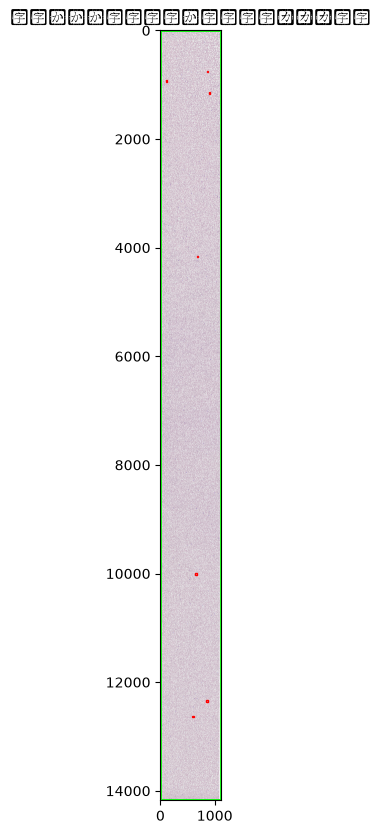

In [4]:
# 組織(細胞)が写っている領域を自動検出し、そこから評価用パッチの座標を決める
## 座標を決め打ちにしない方針:
##   1. WSI全体を安全な低メモリ量で間引き読みし、低解像度オーバービューを作る
##      (get_thumbnail()はlevel_count=1のこのファイルでは全画素デコードが必要になり
##       クラッシュするため使わない)
##   2. 背景(白)でない領域を固定閾値で検出し、組織のバウンディングボックスを
##      level0座標系に変換する
##   3. そのバウンディングボックス内から、実際に組織が写っている座標だけを
##      パッチ位置としてランダムサンプリングする

def build_overview(wsi, downsample=16, strip_height=2000):
    """WSI全体を高さ方向に細切れで読み込み、間引きながら結合した低解像度画像を作る"""
    w, h = wsi.dimensions
    ov_w = max(1, w // downsample)
    rows = []
    for y in range(0, h, strip_height):
        sh = min(strip_height, h - y)
        strip = wsi.read_region((0, y), level=0, size=(w, sh)).convert("RGB")
        strip = strip.resize((ov_w, max(1, sh // downsample)))
        rows.append(np.array(strip))
    return np.vstack(rows)

def find_tissue_bbox(overview, downsample, white_thresh=5):
    """オーバービューから背景(白)でない最大の連結領域を探し、level0座標のbboxを返す"""
    gray = cv2.cvtColor(overview, cv2.COLOR_RGB2GRAY)
    tissue_mask = (gray < (255 - white_thresh)).astype(np.uint8)

    n, labels, stats, _ = cv2.connectedComponentsWithStats(tissue_mask)
    if n <= 1:
        raise ValueError("組織領域が検出できませんでした。white_threshを調整してください。")

    largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    x, y, bw, bh, _ = stats[largest]
    return x * downsample, y * downsample, bw * downsample, bh * downsample

def generate_patch_coords(bbox, patch_size, n_patches, wsi_dims, overview, downsample,
                           min_coverage=0.5, white_thresh=5, margin_ratio=0.05, seed=0):
    """bbox内から組織の被覆率がmin_coverage以上の座標だけをパッチ位置として採用する。

    bboxの四隅・端をそのまま使うと、血液塗抹のような細長い組織では
    端(=塗抹の先端や背景)にヒットしやすく白いパッチの原因になるため、
    オーバービュー上の非白画素の割合(被覆率)を候補点ごとに確認してから採用する。
    """
    tx, ty, tw, th = bbox
    w, h = wsi_dims

    gray_ov = cv2.cvtColor(overview, cv2.COLOR_RGB2GRAY)
    tissue_mask_ov = gray_ov < (255 - white_thresh)

    def coverage(x, y):
        ox0, oy0 = int(x / downsample), int(y / downsample)
        ox1 = max(ox0 + 1, int((x + patch_size) / downsample))
        oy1 = max(oy0 + 1, int((y + patch_size) / downsample))
        region = tissue_mask_ov[oy0:oy1, ox0:ox1]
        return region.mean() if region.size else 0.0

    # bboxの端ぎりぎりを避けるため、内側にマージンを取った範囲からサンプリングする
    margin_x, margin_y = tw * margin_ratio, th * margin_ratio
    x_lo, x_hi = tx + margin_x, min(tx + tw, w) - patch_size - margin_x
    y_lo, y_hi = ty + margin_y, min(ty + th, h) - patch_size - margin_y
    if x_hi < x_lo:
        x_lo, x_hi = tx, min(tx + tw, w) - patch_size
    if y_hi < y_lo:
        y_lo, y_hi = ty, min(ty + th, h) - patch_size

    rng = np.random.default_rng(seed)
    coords = []
    max_attempts = n_patches * 300
    for _ in range(max_attempts):
        if len(coords) >= n_patches:
            break
        x = rng.uniform(x_lo, x_hi)
        y = rng.uniform(y_lo, y_hi)
        if coverage(x, y) >= min_coverage:
            coords.append((int(x), int(y)))

    if len(coords) < n_patches:
        raise ValueError(
            f"被覆率{min_coverage}以上の座標が{len(coords)}/{n_patches}件しか見つかりませんでした。"
            "min_coverageを下げるか、n_patchesを減らしてください。"
        )
    return coords

DOWNSAMPLE = 16
overview = build_overview(wsi, downsample=DOWNSAMPLE)
tissue_bbox = find_tissue_bbox(overview, downsample=DOWNSAMPLE)
print("検出された組織領域(level0座標): x=%d, y=%d, w=%d, h=%d" % tissue_bbox)

coords = generate_patch_coords(tissue_bbox, patch_size, n_patches=7, wsi_dims=wsi.dimensions,
                                overview=overview, downsample=DOWNSAMPLE, min_coverage=0.5)
print("自動生成されたパッチ座標:", coords)

# 検出した組織領域とパッチ位置をオーバービュー上に可視化
fig, ax = plt.subplots(figsize=(6, 10))
ax.imshow(overview)
tx, ty, tw, th = tissue_bbox
ax.add_patch(plt.Rectangle((tx / DOWNSAMPLE, ty / DOWNSAMPLE), tw / DOWNSAMPLE, th / DOWNSAMPLE,
                            edgecolor='lime', facecolor='none', linewidth=2))
for (x, y) in coords:
    ax.add_patch(plt.Rectangle((x / DOWNSAMPLE, y / DOWNSAMPLE),
                                patch_size / DOWNSAMPLE, patch_size / DOWNSAMPLE,
                                edgecolor='red', facecolor='none', linewidth=1))
ax.set_title("検出された組織領域と自動生成パッチ位置")
plt.show()

wsi_tests = [wsi.read_region(location=c, level=0, size=(patch_size, patch_size)).convert("RGB") for c in coords]


In [ ]:
# 自作関数 pickup_wbc_threshの目的：切り出した塗抹標本画像の中から、白血球（WBC: White Blood Cell）らしき細胞の位置を特定して枠で囲むこと
## 流れ
### 大津の二値化で細胞と背景を分ける
### 60×60のパネルをずらしながら画像をスキャンする
### 色判定：60×60のパネルの中で，青みが強く赤みが弱い(青が一定以上・赤が一定以下)場所を白血球とみなす(白血球の核は青紫に染まり赤血球は赤く染まる性質)
### 近くにある反応を1つにまとめる：
def pickup_wbc_thresh(wsi_test, size=60, blue_thresh=150, red_thresh=150):
    image_array = np.array(wsi_test) #np.arrayに変換
    print(image_array.shape)
    pil_img = Image.fromarray(image_array) #PIL Image

    # 背景と細胞を分ける
    gray = cv2.cvtColor(image_array, cv2.COLOR_RGB2GRAY) #gray scale

    ret, binary = cv2.threshold(gray, 10, 255, cv2.THRESH_OTSU + cv2.THRESH_BINARY_INV) #OTSU
    print("OHTSU Thresh :", ret)
    # cv2.threshold…大津の二値化を使って背景を黒，細胞を白にした画像(=binary)を作る

    ## 背景を真っ黒にして，細胞の色だけを残す計算
    # 元のコード…img_pro = np.array([((np.array(image_array[i]).T)*(np.array(binary[i])*np.array([1/255]))).T for i in range(len(image_array))]) #OTSU+color Image
    img_pro = cv2.bitwise_and(image_array, image_array, mask=binary)
    ## 元の画像と背景黒・細胞白の画像(=binary)を掛け合わせて背景を完全に黒くし，細胞の色だけを残す処理をしている

    pil_img = Image.fromarray(img_pro.astype(np.uint8))

    x = 0
    y = 0
    X = [0, 0]
    Y = [0, 0]
    blue_mean_max = 0

    loc_lst = []
    ap = loc_lst.append

    # 60×60の大きさで画像をスキャンして色を判定
    ## for文で縦横10ピクセルずつずらしながらsizeのパッチを切り出す
    for i in range(0, image_array.shape[0], 10):
        for j in range(0, image_array.shape[1], 10):
            pil_img_batch = pil_img.crop((i, j, i+size, j+size))
            numpy_image = np.array(pil_img_batch)
            # OpenCVの色配列は[縦, 横, 色(RGB)]となっている
            blue_mean = numpy_image[:, :, 2].mean() # パッチ内の青色の平均値
            # [:, :, 2]は青色
            red_mean = numpy_image[:, :, 0].mean() # パッチ内の赤色の平均値
            # [:, :, 0]は赤色

            # もし青が強くて，赤が弱ければ白血球とみなす
            if blue_mean > blue_thresh and red_mean < red_thresh:  # 青がblue_threshより高く，赤色がred_threshより低い場所を白血球の候補としてloc_lstに記録
                ap([i, j]) # loc_lstに座標を保存 (ap は loc_lst.append のこと)
            else:
                pass
    area_lst = []
    ap_area = area_lst.append
    del_area = area_lst.remove

    # 見つけた座標を大きな枠にまとめる
    ## 青が強い箇所の座標は，1つの白血球に対して複数箇所検出されているはず
    ## 白血球候補として検出された，近接している座標は1つの大きな四角形(area)に合体させる処理をおkの合う
    for loc in loc_lst:
        for area in area_lst:
            if (area[0][0]-2*size <= loc[0] <= area[0][1]+2*size) and (area[1][0]-2*size <= loc[1] <= area[1][1]+2*size):
            # もし見つけた座標locが既存のareaの近く
            # (locのx座標が既存areaのx範囲を上下に2*sizeした範囲)にあったら…
                # 枠の大きさを広げて更新する(合体させる)
                xmin = min(loc[0], area[0][0])
                xmax = max(loc[0]+size, area[0][1])
                ymin = min(loc[1], area[1][0])
                ymax = max(loc[1]+size, area[1][1])
                del_area(area) # 古い小さな枠を消す
                ap_area([[xmin, xmax], [ymin, ymax]]) # 大きくなった枠を登録
                break
        else:
            # どの枠の近くにもなければ，新しい独立した枠として登録
            ap_area([[loc[0], loc[0]+size], [loc[1], loc[1]+size]])


    # 緑色の枠を描画して画面に表示
    ## 四角形の4つの角の座標を作り，小さすぎるもの(size/2未満)は除外する
    ## (以前は固定値30でフィルタしていたが、これはsize=60前提の値だったため、
    ##  sizeを変えても自動的に整合するようsize/2に変更)
    pickup_wbc_lst = [[[i[0][0]-size/2, i[1][0]-size/2],
    [i[0][0]-size/2, i[1][1]+size/2],
    [i[0][1]+size/2, i[1][1]+size/2],
    [i[0][1]+size/2, i[1][0]-size/2],
    [i[0][0]-size/2, i[1][0]-size/2]] for i in area_lst if i[0][1]-i[0][0] > size/2 and i[1][1]-i[1][0] > size/2]

    wbc_area = np.array(pickup_wbc_lst)
    lc = LineCollection(wbc_area, color='lime', linestyle='dotted')

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

    # 左側(ax1)に処理前の元画像を表示
    ax1.imshow(image_array) # 元画像を表示
    ax1.set_title("Before: Original")

    # 右側(ax2)に緑枠を重ねた結果を表示
    ax2.imshow(image_array)
    ax2.add_collection(lc) # 元画像の上に枠線を重ねる
    ax2.set_title("After: WBC detection")

    plt.show()


(800, 800, 3)
OHTSU Thresh : 186.0


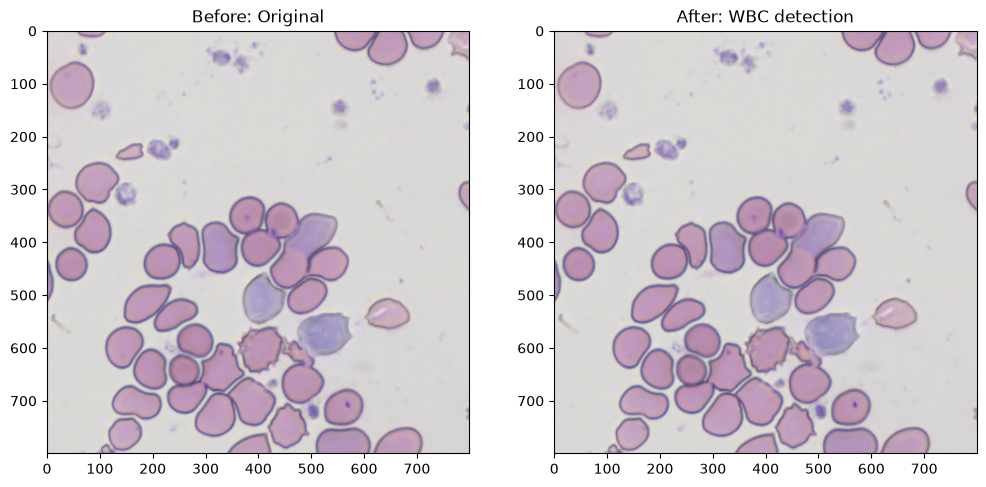

(800, 800, 3)
OHTSU Thresh : 182.0


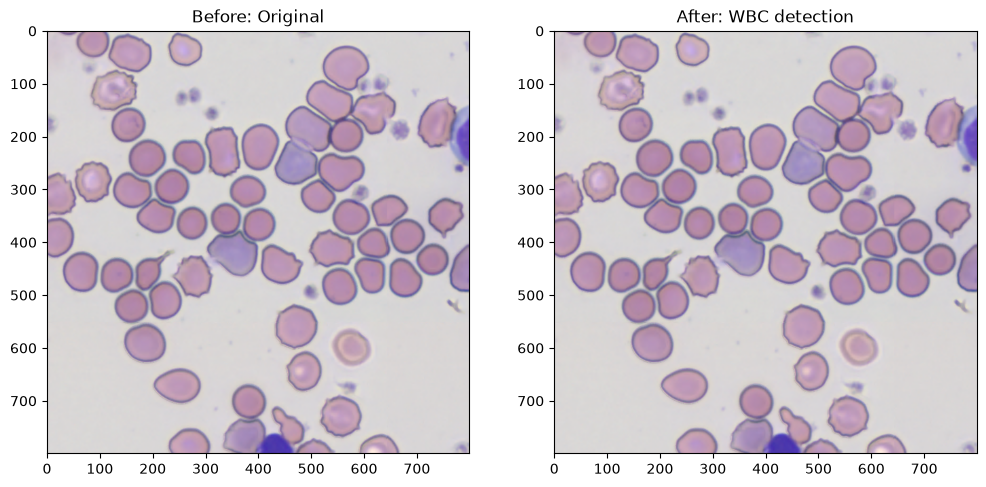

(800, 800, 3)
OHTSU Thresh : 179.0


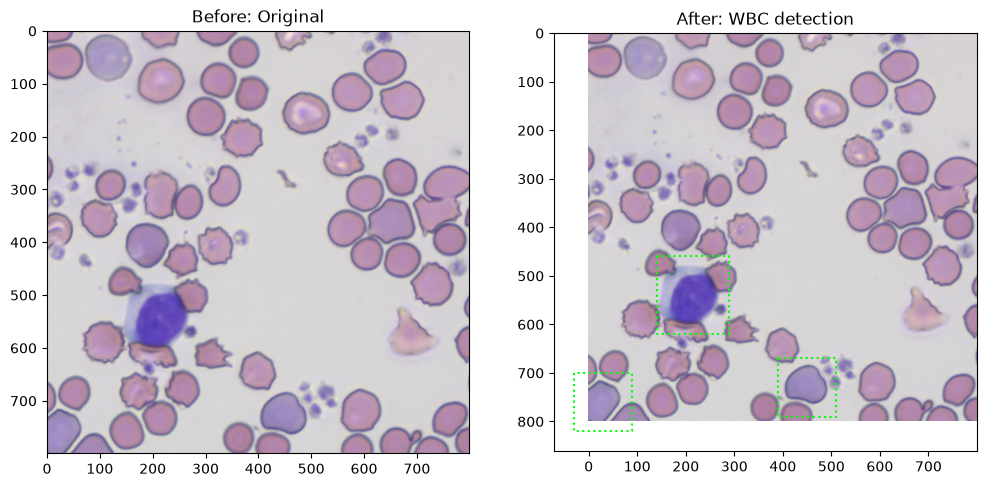

(800, 800, 3)
OHTSU Thresh : 180.0


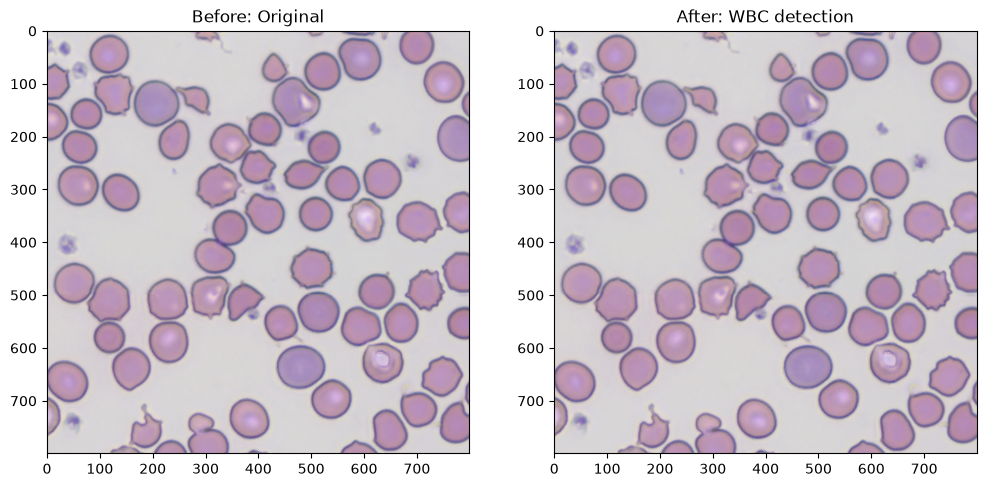

(800, 800, 3)
OHTSU Thresh : 180.0


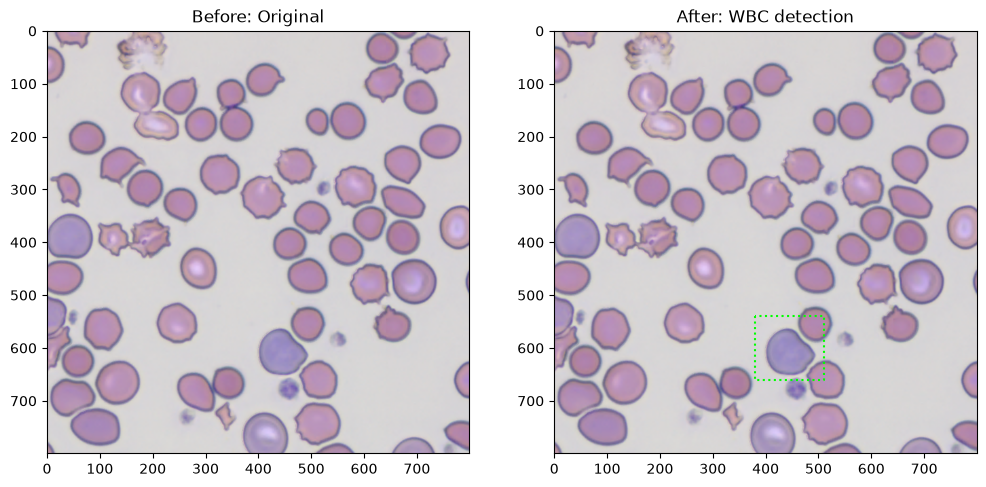

(800, 800, 3)
OHTSU Thresh : 179.0


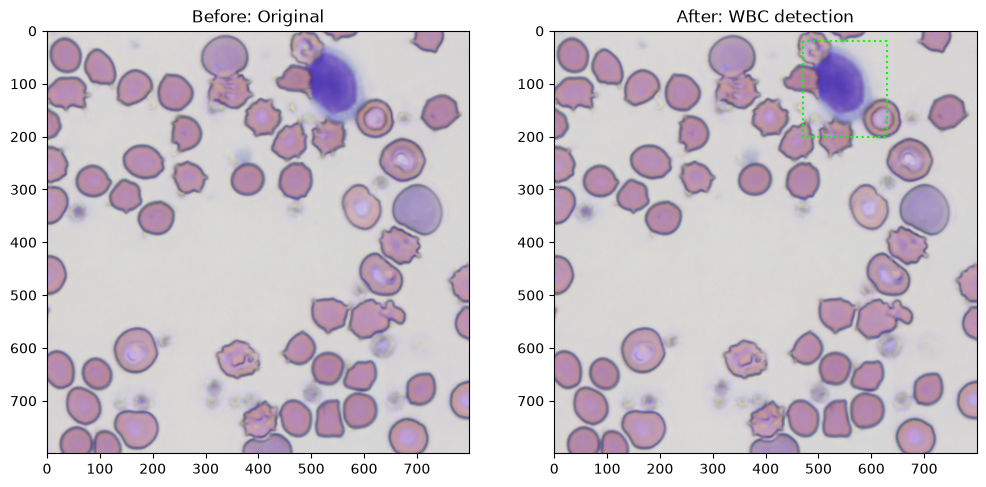

(800, 800, 3)
OHTSU Thresh : 183.0


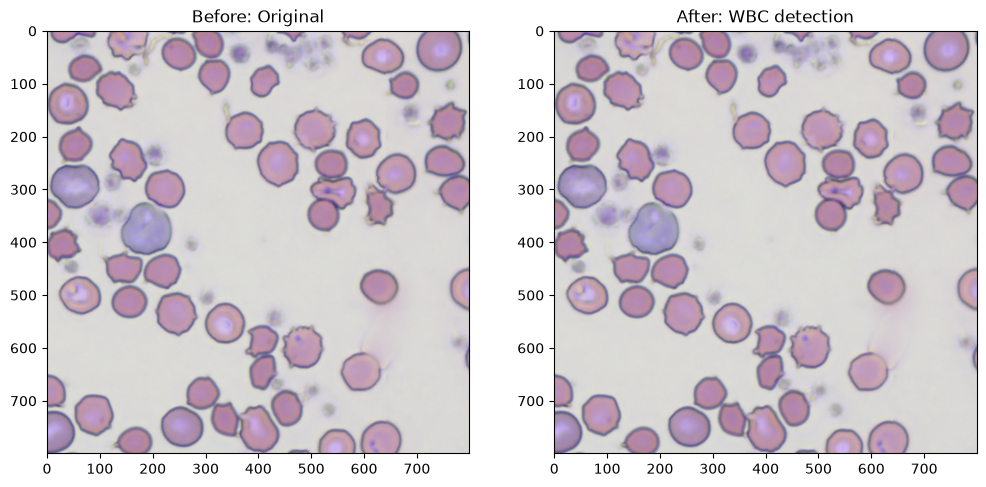

In [88]:
for wsi_test in wsi_tests:
    pickup_wbc_thresh(wsi_test, size=60, blue_thresh=180)
# size…検出枠のサイズ(元は60)
# blue_thresh…青さの程度(元は150)

### 260403_lps_iwasaka_Image10

In [7]:
path_1 = "/workspace/filesrv02/nakagawa/DigitalHematology/data/testdata_to_nakagawa/s260325010260810247.tif"
wsi = OpenSlide(path_1)
# 開いた巨大画像データそのものを格納した変数
patch_size=200*4
# patch_size：切り出す画像の1辺の長さ
## 掛け算にしている理由：基本は200だけど，今回は2倍のサイズで切り出したいという意図など？

In [8]:
# 画像のサイズを知る(横, 縦)
wsi.dimensions

(16010, 226906)

In [9]:
# 手動で領域を乱択
wsi_test1 = wsi.read_region(location=(8000, 10000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test2 = wsi.read_region(location=(8000, 20000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test3 = wsi.read_region(location=(8000, 40000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test4 = wsi.read_region(location=(8000, 60000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test5 = wsi.read_region(location=(8000, 80000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test6 = wsi.read_region(location=(8000, 100000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test7 = wsi.read_region(location=(8000, 120000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_tests = [wsi_test1, wsi_test2, wsi_test3, wsi_test4, wsi_test5, wsi_test6, wsi_test7]

(800, 800, 3)
OHTSU Thresh : 187.0


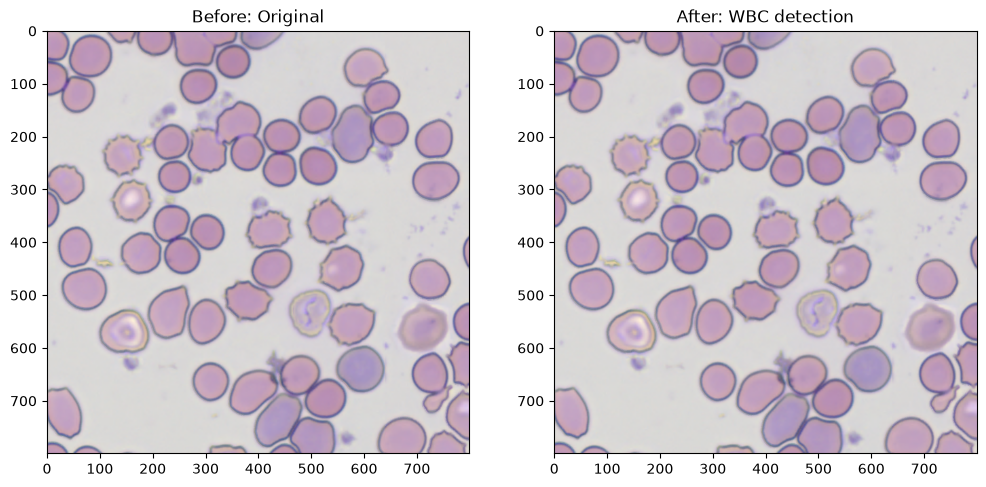

(800, 800, 3)
OHTSU Thresh : 183.0


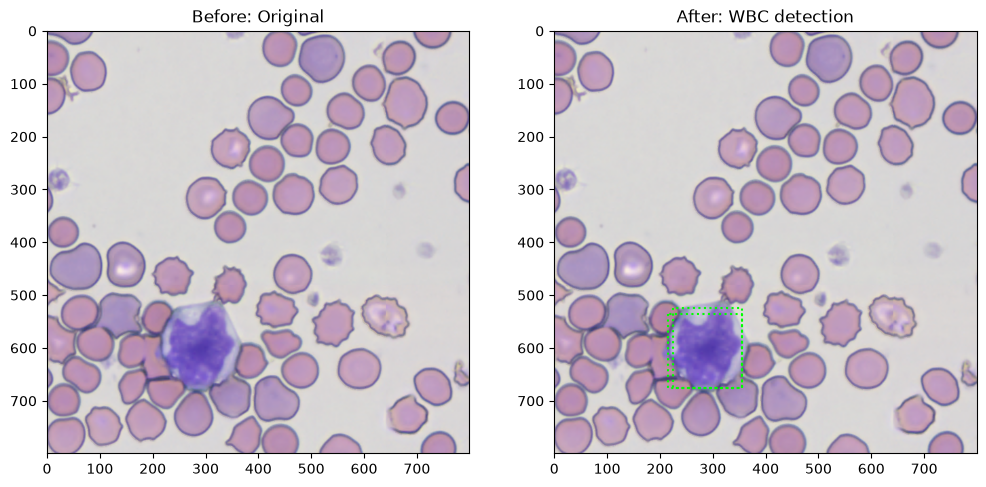

(800, 800, 3)
OHTSU Thresh : 182.0


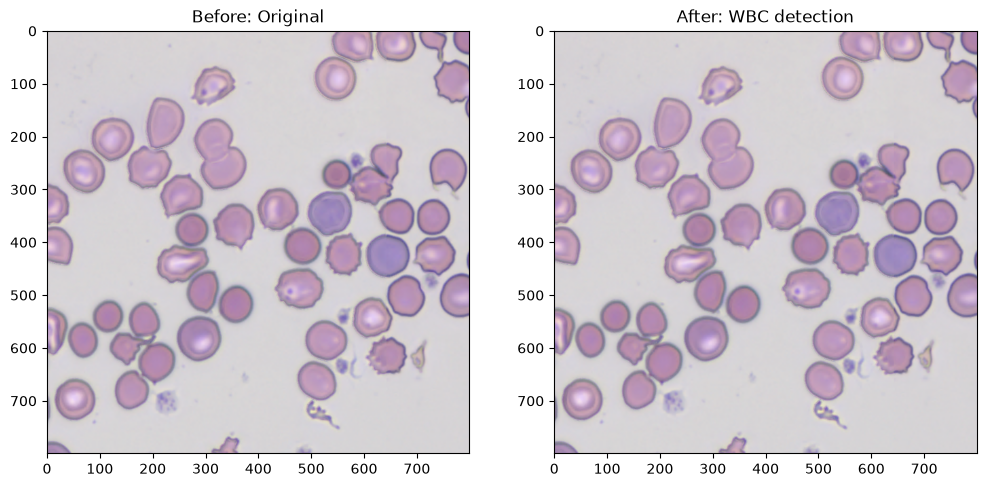

(800, 800, 3)
OHTSU Thresh : 179.0


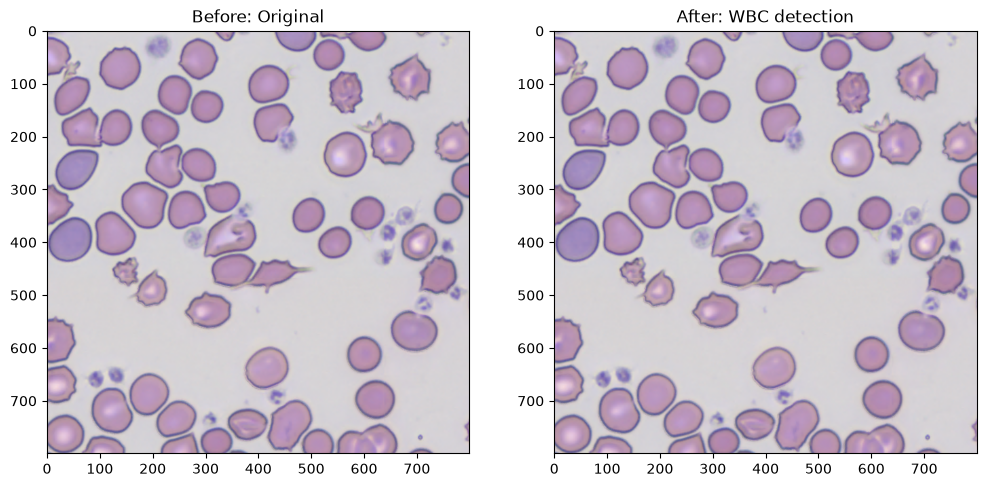

(800, 800, 3)
OHTSU Thresh : 179.0


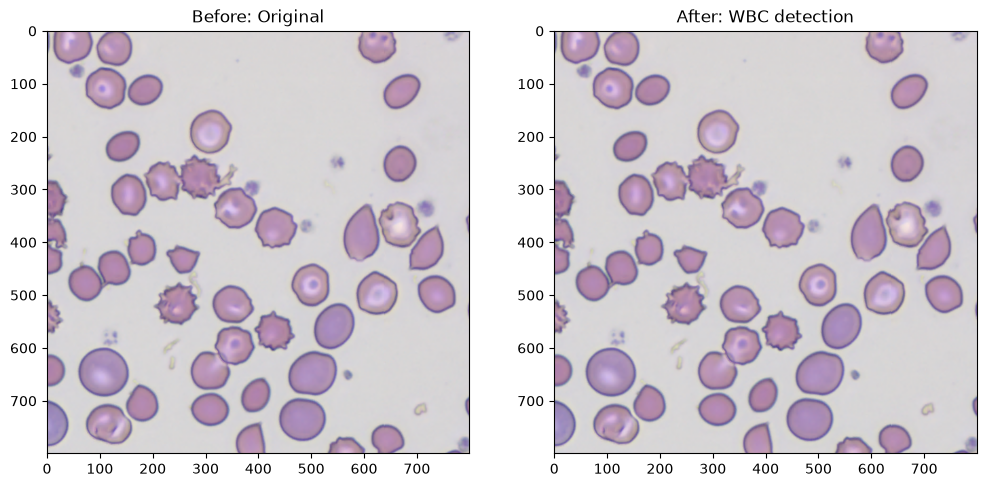

(800, 800, 3)
OHTSU Thresh : 183.0


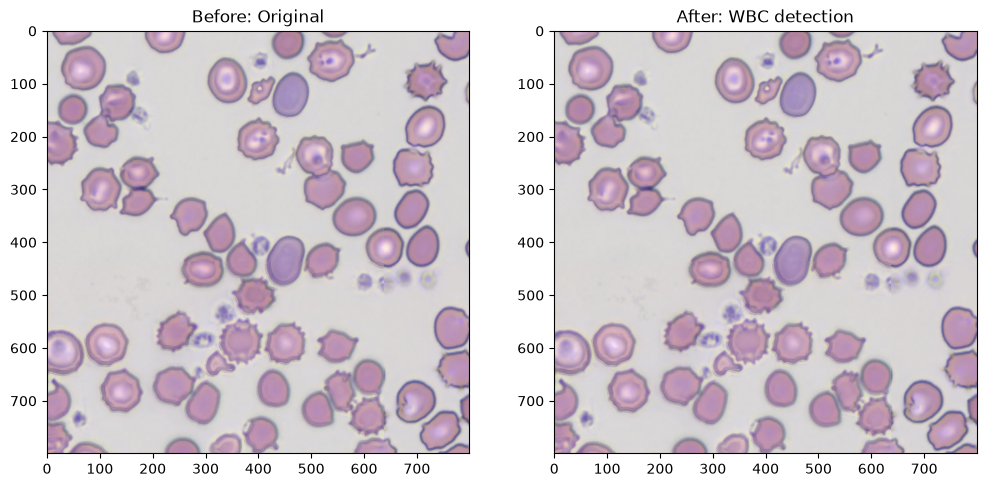

(800, 800, 3)
OHTSU Thresh : 183.0


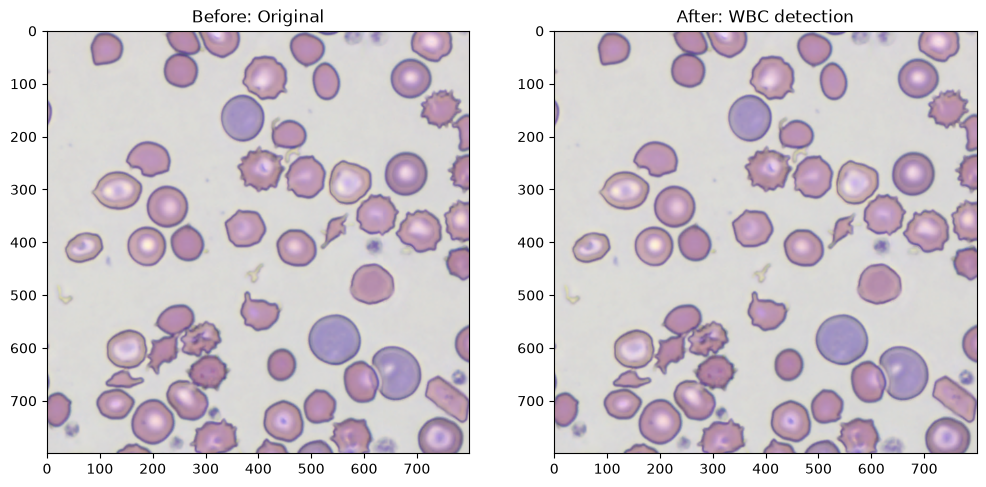

In [11]:
for wsi_test in wsi_tests:
    pickup_wbc_thresh(wsi_test, size=10, blue_thresh=190)
# size…検出枠のサイズ(元は60)
# blue_thresh…青さの程度(元は150)

### 260403_lps_iwasaka_Image8

In [ ]:
# 骨髄塗抹
# メイ・ギムザ染色(うちで使っている)
# ライト・ギムザ染色

In [92]:
path_1 = "/workspace/filesrv02/nakagawa/DigitalHematology/data/testdata_to_nakagawa/s260325011260810248.tif"
wsi = OpenSlide(path_1)
# 開いた巨大画像データそのものを格納した変数
patch_size=200*4
# patch_size：切り出す画像の1辺の長さ
## 掛け算にしている理由：基本は200だけど，今回は2倍のサイズで切り出したいという意図など？

In [93]:
# 画像のサイズを知る(横, 縦)
wsi.dimensions

(16002, 229058)

In [95]:
# 手動で領域を乱択
wsi_test1 = wsi.read_region(location=(7000, 10000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test2 = wsi.read_region(location=(7000, 20000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test3 = wsi.read_region(location=(7000, 40000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test4 = wsi.read_region(location=(7000, 60000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test5 = wsi.read_region(location=(7000, 80000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test6 = wsi.read_region(location=(7000, 100000), level=0, size=(patch_size,patch_size)).convert("RGB")
wsi_test7 = wsi.read_region(location=(7000, 120000), level=0, size=(patch_size,patch_size)).convert("RGB")

wsi_tests = [wsi_test1, wsi_test2, wsi_test3, wsi_test4, wsi_test5, wsi_test6, wsi_test7]

(800, 800, 3)
OHTSU Thresh : 183.0


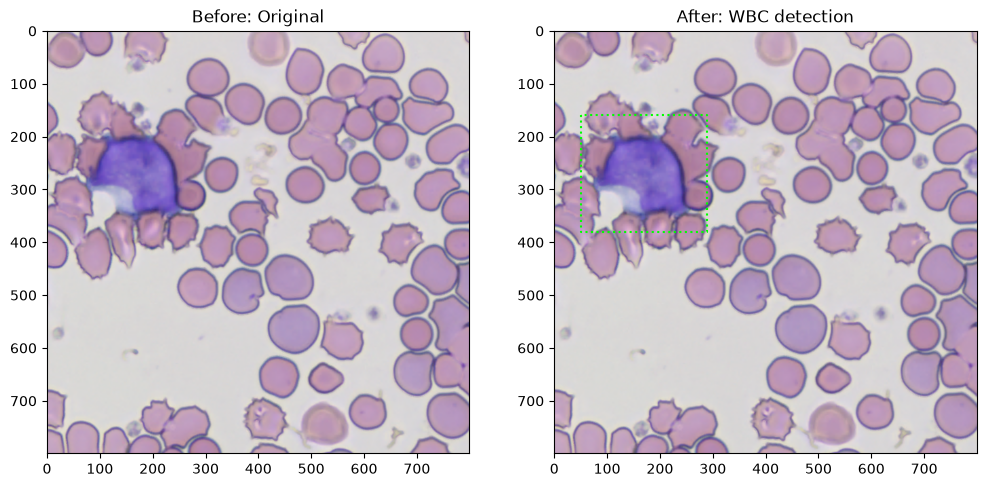

(800, 800, 3)
OHTSU Thresh : 183.0


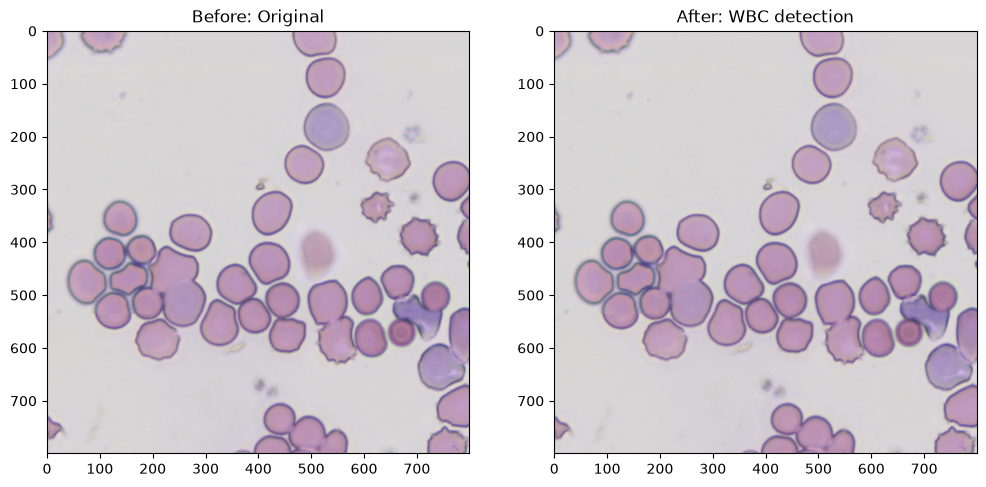

(800, 800, 3)
OHTSU Thresh : 182.0


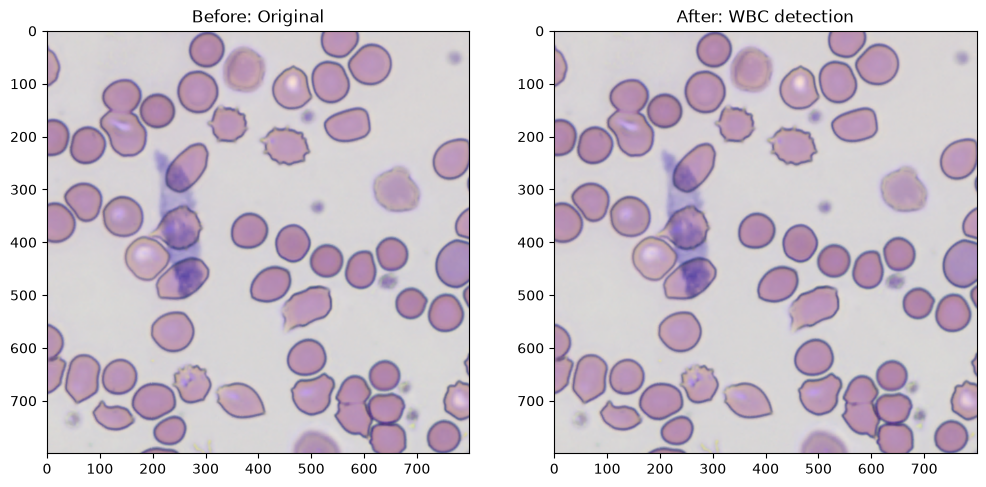

(800, 800, 3)
OHTSU Thresh : 182.0


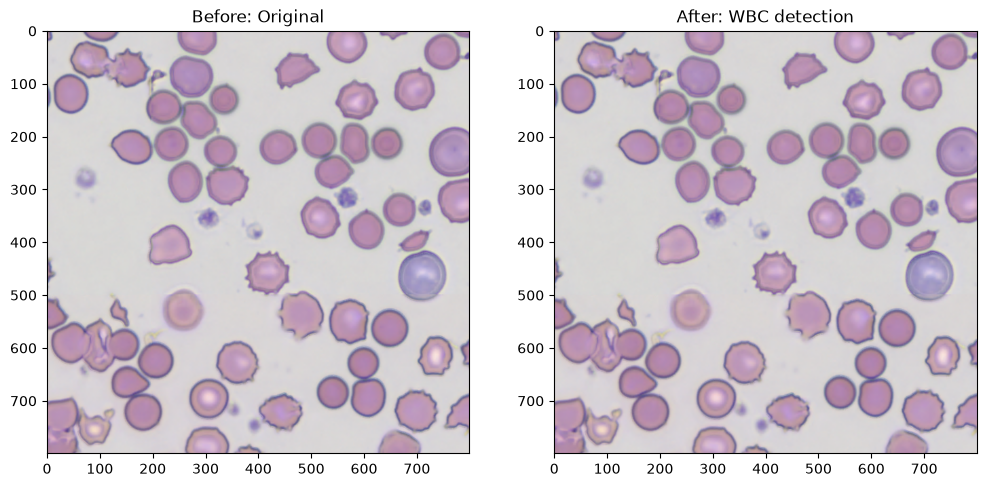

(800, 800, 3)
OHTSU Thresh : 183.0


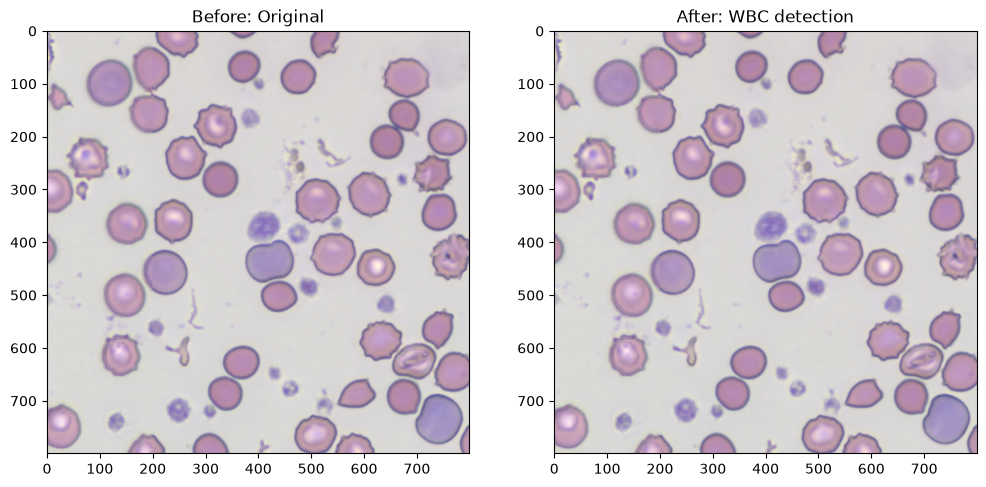

(800, 800, 3)
OHTSU Thresh : 181.0


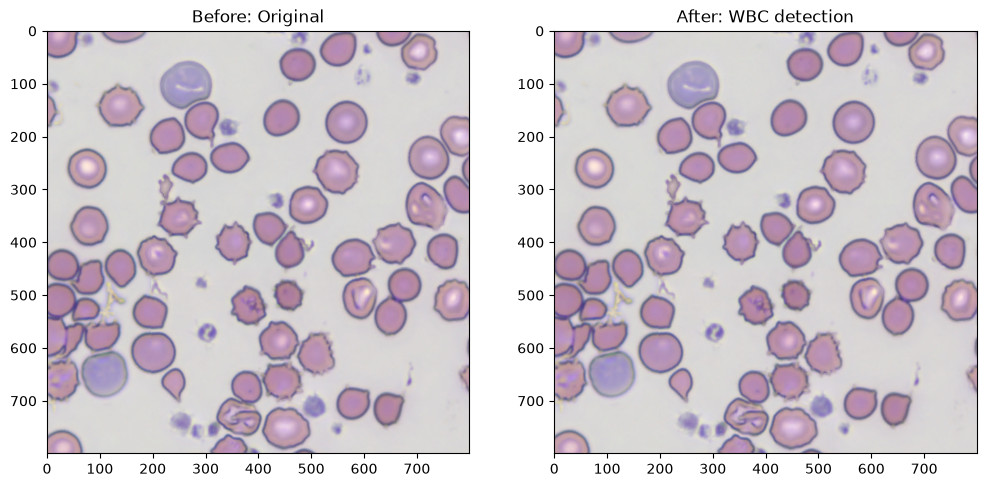

(800, 800, 3)
OHTSU Thresh : 181.0


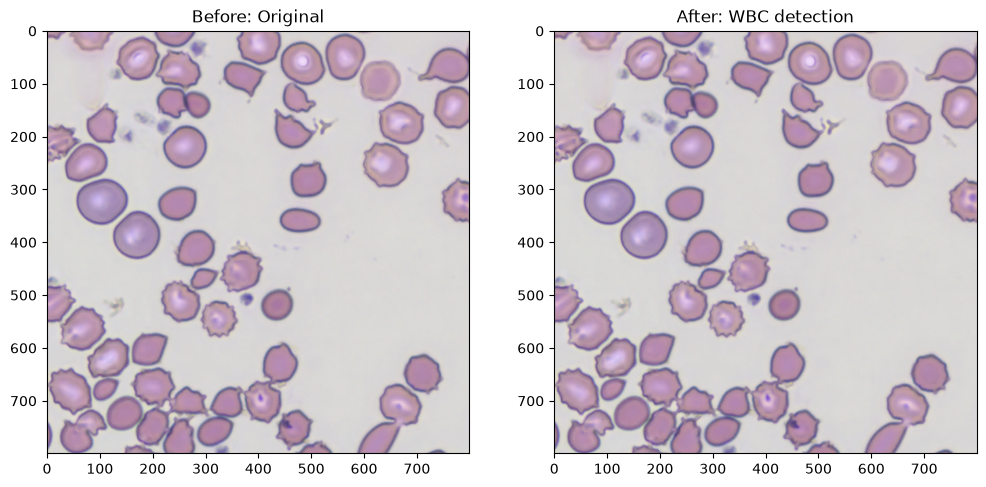

In [96]:
for wsi_test in wsi_tests:
    pickup_wbc_thresh(wsi_test, size=60, blue_thresh=180)
# size…検出枠のサイズ(元は60)
# blue_thresh…青さの程度(元は150)